# Exploratory Data Analysis — `eg_drugs.csv`
### Egyptian Pharmaceutical Products Dataset

**Scope of this notebook:** Phase 1 (Inspection) → Phase 8 (EDA Summary) + Phase 9 (Recommendations for a future ML stage).
**No machine learning, modeling, or prediction is performed here** — this is a pure data understanding / EDA notebook.

Author workflow follows the standard data-analysis lifecycle: Load → Inspect → Assess Quality → Clean → Understand Features → Outliers → Univariate/Bivariate/Multivariate EDA → Key Questions → Summary → Next steps.

## 1. Import Libraries

In [1]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Display / plotting settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.unicode_minus'] = False

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load Dataset

In [2]:
# 2. Load Dataset
df = pd.read_csv('eg_drugs.csv')
print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")

Dataset loaded: 26,562 rows x 25 columns


## 3. Initial Inspection

We look at the raw data *before* making any assumption about what it represents.

In [3]:
# First 5 rows
df.head()

,id,name,arabic,active,company,price,oldprice,availability,barcode,slug,units,description,uses,matched_fda_ingredients,uses_summary,uses_summary_en,warning_high_blood_pressure,warning_diabetes,warning_pregnancy,warning_lactation,warning_kidney,warning_liver,warning_heart,warnings_summary,warnings_summary_en
0,1,1 2 3 (one two three) syrup 120 ml,ون تو ثري شراب 120 مل,Chlorpheniramine+paracetamol+pseudoephedrine,Hikma,40.00.,32.00.,NaN,6221000000010,1,1,Cold drugs,تخفيف أعراض نزلات البرد والإنفلونزا مثل الصداع...,pseudoephedrine | chlorpheniramine,تخفيف أعراض نزلات البرد والإنفلونزا مثل الصداع...,temporarily relieves nasal congestion due to t...,1,1,1,1,0,0,1,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...
1,2,1 2 3 (one two three) 20 f.c.tabs,ون تو ثري 20 قرص,Chlorpheniramine+paracetamol+pseudoephedrine,Hikma,40.00.,24.00.,NaN,6221000000010,2,2,Cold drugs,تخفيف أعراض نزلات البرد والإنفلونزا مثل الصداع...,pseudoephedrine | chlorpheniramine,تخفيف أعراض نزلات البرد والإنفلونزا مثل الصداع...,temporarily relieves nasal congestion due to t...,1,1,1,1,0,0,1,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...
2,3,5-fluorouracil-ebewe 250mg/5ml i.v. vial,فلورويوراسيل 250مجم/5مل فيال وريد,Fluorouracil,Shanghai xudong haipu pharmaceutical > acdima ...,74.00.,50.00.,NaN,9088881320685,3,1,Antineoplastic,يُستخدم في علاج بعض أنواع سرطان القولون والمست...,fluorouracil,يُستخدم في علاج بعض أنواع سرطان القولون والمست...,Fluorouracil Cream is recommended for the topi...,0,0,1,0,0,0,0,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...
3,4,mooagar sachets,مو اجار 2جم اكياس,agar,hexa pharma company,75,NaN,3710.0,NaN,mooagar-sachets,1,jaundice,الصفراء عند حديثي الولادة يُستخدم كمُليّن طبيع...,NaN,الصفراء عند حديثي الولادة يُستخدم كمُليّن طبيع...,No registered indications.,0,0,0,0,0,0,0,لا توجد تحذيرات خاصة مسجلة لهذه الحالات. استشر...,No special warnings registered for these condi...
4,5,limitless lactoferrin 100 mg 30 sachets,ليمتلس لاكتوفيرين 100 مجم 30 كيس,lactoferrin,eva pharma,485,385,3711.0,NaN,limitless-lactoferrin-100-mg-30-sachets,1,iron supplement,يساعد في علاج الأنيميا الناتجة عن نقص الحديد ل...,NaN,يساعد في علاج الأنيميا الناتجة عن نقص الحديد ل...,No registered indications.,0,0,0,0,0,0,0,لا توجد تحذيرات خاصة مسجلة لهذه الحالات. استشر...,No special warnings registered for these condi...


In [4]:
# Last 5 rows
df.tail()

,id,name,arabic,active,company,price,oldprice,availability,barcode,slug,units,description,uses,matched_fda_ingredients,uses_summary,uses_summary_en,warning_high_blood_pressure,warning_diabetes,warning_pregnancy,warning_lactation,warning_kidney,warning_liver,warning_heart,warnings_summary,warnings_summary_en
26557,33935,zinobacilly oral drops 10 ml,زينوباسيلي قطرات للفم 10 مل,lactobacillus+vitamin d3,dawak pharm,135,125,0.0,NaN,zinobacilly-oral-drops-10-ml,1,probiotics & lactase enzyme,يدعم صحة الجهاز الهضمى,lactobacillus | vitamin d,يدعم صحة الجهاز الهضمى.,"1,For alleviating symptoms of inflammatory rea...",0,0,0,0,0,0,0,لا توجد تحذيرات خاصة مسجلة لهذه الحالات. استشر...,No special warnings registered for these condi...
26558,33936,zma 90 veg. caps. (now),زد ام ايه 90 كبسولة برطمان,zinc+magnesium+vitamin b6,soficopharm,2200,1800,0.0,NaN,zma-90-veg.-caps.--now-,1,multivitamin,NaN,magnesium | vitamin b | zinc,يُستخدم كـ فيتامين ج و فيتامين د و فيتامين ب12...,treats frequent heartburn (occurs 2 or more da...,0,0,1,1,0,0,0,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...
26559,33938,zolmigo 2.5 mg 3 orodispersible tabs,زولميجو 2.5 مجم 3 قرص,zolmitriptan,life,22.5,NaN,0.0,NaN,zolmigo-2.5-mg-3-orodispersible-tabs,1,antimigraine.vasoconstrictor agents.selective ...,يستخدم فى علاج الصداع النصفى,zolmitriptan,يستخدم فى علاج الصداع النصفى.,1 INDICATIONS AND USAGE ZOLMITRIPTAN NASAL SPR...,1,0,0,0,0,1,1,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...
26560,33939,zonnet cream 30 gram,زونيت كريم 30 جرام,panthenol + ch-cmc + tea tree + honey,hexa pharma international,65,NaN,1.0,NaN,zonnet-cream-30-gram,1,healing cream,NaN,tea tree | honey | panthenol,دواعي الاستعمال: temporary relieves: ■ cough d...,temporary relieves: ■ cough due to cold ■ occa...,0,0,0,0,0,0,0,لا توجد تحذيرات خاصة مسجلة لهذه الحالات. استشر...,No special warnings registered for these condi...
26561,33940,zymalge topical gel 50 gm,زيمالجي جل 50 جم,antimicrobial enzymes+alginate+co-polymers+hya...,pharma mart,275,245,0.0,745114711007,zymalge-topical-gel-50-gm,1,skin care.healing,جل مضاد للالتهابات ويساعد على علاج وترميم البش...,hyaluronic | allantoin | potassium sorbate | a...,جل مضاد للالتهابات ويساعد على علاج وترميم البش...,reduces underarm wetness || Apply as needed. |...,0,0,1,1,1,0,0,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...


In [5]:
# A random sample (helps catch patterns that head()/tail() might hide)
df.sample(5, random_state=42)

,id,name,arabic,active,company,price,oldprice,availability,barcode,slug,units,description,uses,matched_fda_ingredients,uses_summary,uses_summary_en,warning_high_blood_pressure,warning_diabetes,warning_pregnancy,warning_lactation,warning_kidney,warning_liver,warning_heart,warnings_summary,warnings_summary_en
10125,13901,ambroxol 75mg s.r 10 caps,امبروكسول ممتد المفعول 75 10 كبسولة,ambroxol,glaxo smithkline,9.25,NaN,0.0,6221045001492,ambroxol-75mg-s.r-10-caps,1,mucolytic,NaN,NaN,لا توجد دواعي استعمال مسجلة.,No registered indications.,0,0,0,0,0,0,0,لا توجد تحذيرات خاصة مسجلة لهذه الحالات. استشر...,No special warnings registered for these condi...
21459,27950,potfact 99 mg 60 tab,بوتفاكت 99 مجم 60 قرص,potassium citrate,fact pharma,120,NaN,0.0,NaN,potfact-99-mg-60-tab,1,minerals,NaN,potassium citrate,دواعي الاستعمال: 1 INDICATIONS AND USAGE Potas...,1 INDICATIONS AND USAGE Potassium citrate exte...,0,1,0,0,1,0,0,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...
4745,5403,calcidol calcium 30 tabs,كالسيدول كالسيوم 30 قرص,calcium+vitamin d+magnesium+zinc,drug pharma egypt,76,NaN,2.0,NaN,calcidol-calcium-30-tabs,3,calcium with vitamin d,NaN,calcium | vitamin d | magnesium | zinc,يُستخدم كـ فيتامين ج و فيتامين أ.,1 INDICATIONS AND USAGE Calcium acetate is a p...,0,0,0,0,1,0,0,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...
16560,22100,lucovital anti-lice cream lotion 75 ml,لوكوفيتال انتي لايس لوشن 75 مل,NaN,pk benelux bv >,180,NaN,0.0,NaN,lucovital-anti-lice-cream-lotion-75-ml,1,scabicide,علاج انتشار القمل في فروة الرأس -- الحماية من ...,NaN,علاج انتشار القمل في فروة الرأس -- الحماية من ...,No registered indications.,0,0,0,0,0,0,0,لا توجد تحذيرات خاصة مسجلة لهذه الحالات. استشر...,No special warnings registered for these condi...
13702,18504,letracitolin syrup 120 ml,ليتراسيتولين شراب 120 مل,citicoline,medicolena,210,150,0.0,NaN,letracitolin-syrup-120-ml,1,cerebral circulatory enhancer,• يساعد في تحسين الذاكرة والتركيز والانتباه في...,NaN,• يساعد في تحسين الذاكرة والتركيز والانتباه في...,No registered indications.,0,0,0,0,0,0,0,لا توجد تحذيرات خاصة مسجلة لهذه الحالات. استشر...,No special warnings registered for these condi...


In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print()
print("Column names:")
for c in df.columns:
    print(" -", c)

Number of rows: 26562
Number of columns: 25

Column names:
 - id
 - name
 - arabic
 - active
 - company
 - price
 - oldprice
 - availability
 - barcode
 - slug
 - units
 - description
 - uses
 - matched_fda_ingredients
 - uses_summary
 - uses_summary_en
 - warning_high_blood_pressure
 - warning_diabetes
 - warning_pregnancy
 - warning_lactation
 - warning_kidney
 - warning_liver
 - warning_heart
 - warnings_summary
 - warnings_summary_en


In [7]:
df.dtypes

id                               int64
name                               str
arabic                             str
active                             str
company                            str
price                              str
oldprice                           str
availability                   float64
barcode                            str
slug                               str
units                            int64
description                        str
uses                               str
matched_fda_ingredients            str
uses_summary                       str
uses_summary_en                    str
warning_high_blood_pressure      int64
warning_diabetes                 int64
warning_pregnancy                int64
warning_lactation                int64
warning_kidney                   int64
warning_liver                    int64
warning_heart                    int64
warnings_summary                   str
warnings_summary_en                str
dtype: object

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26562 entries, 0 to 26561
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           26562 non-null  int64  
 1   name                         26562 non-null  str    
 2   arabic                       26562 non-null  str    
 3   active                       23805 non-null  str    
 4   company                      26252 non-null  str    
 5   price                        26557 non-null  str    
 6   oldprice                     11362 non-null  str    
 7   availability                 26219 non-null  float64
 8   barcode                      10532 non-null  str    
 9   slug                         26561 non-null  str    
 10  units                        26562 non-null  int64  
 11  description                  25427 non-null  str    
 12  uses                         8107 non-null   str    
 13  matched_fda_ingredients    

In [9]:
# Numeric columns summary
df.describe()

,id,availability,units,warning_high_blood_pressure,warning_diabetes,warning_pregnancy,warning_lactation,warning_kidney,warning_liver,warning_heart
count,26562.000000,26219.000000,26562.000000,26562.000000,26562.000000,26562.000000,26562.000000,26562.000000,26562.000000,26562.000000
mean,17276.624915,4.005035,1.864167,0.121075,0.117950,0.265831,0.164784,0.234470,0.153302,0.199458
std,10150.040713,61.688500,4.609505,0.326221,0.322556,0.441783,0.370993,0.423675,0.360285,0.399600
min,1.000000,-3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7746.250000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,17959.500000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,26125.250000,1.000000,2.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,33940.000000,3837.000000,500.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [10]:
# Summary for ALL columns (numeric + text), to see text-column stats too
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,26562.0,NaN,NaN,NaN,17276.624915,10150.040713,1.0,7746.25,17959.5,26125.25,33940.0
name,26562,26557,دليل دواء مصر,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arabic,26562,26403,دليل دواء مصر,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
active,23805,9102,amoxicillin+clavulanic acid,122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company,26252,5533,eva pharma,502,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,26557,2319,120,485,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldprice,11362,1383,60,218,NaN,NaN,NaN,NaN,NaN,NaN,NaN
availability,26219.0,NaN,NaN,NaN,4.005035,61.6885,-3.0,0.0,0.0,1.0,3837.0
barcode,10532,10139,6224007326312,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
slug,26561,26560,bio-hair-lotion-100-ml,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### What does this dataset represent?

Based on the columns and their content (not on the filename), this is a **product-level catalog of pharmaceutical / pharmacy items sold in Egypt** — most likely scraped from an online Egyptian drug-directory / pharmacy website. Each row is **one product listing** (a specific pack/variant of a medicine, supplement, or personal-care item), not a patient, prescription, or hospital record.

Evidence for this:
- `name` / `arabic`: product names in English and Arabic, often including pack size ("120 ml", "20 tab").
- `active`: the active pharmaceutical ingredient(s), sometimes combinations joined with `+`.
- `company`: the manufacturer.
- `price` / `oldprice`: current and previous price in EGP.
- `barcode`: product barcode (GTIN/EAN) — many missing, and not unique (a barcode can represent a product line rather than a single pack).
- `description`: a short internal category/therapeutic-class tag (e.g. "hair care", "antineoplastic", "psychiatric.antidepressants").
- `uses`, `uses_summary`, `uses_summary_en`: free-text descriptions of what the product is used for (Arabic long-form, Arabic short-form, and an English text that looks pulled from FDA drug-label boilerplate — and is **often mismatched** to the actual product, see Data Quality section).
- `matched_fda_ingredients`: ingredient names matched against an FDA ingredient list.
- `warning_*` columns: binary (0/1) flags for whether the product carries a caution for high blood pressure, diabetes, pregnancy, lactation, kidney disease, liver disease, and heart disease — clearly derived/engineered from `warnings_summary`.
- `warnings_summary` / `warnings_summary_en`: the human-readable Arabic/English text those flags were extracted from.

### Column meaning, based only on the data

| Column | Likely meaning |
|---|---|
| `id` | Unique row identifier (integer, unique, no gaps needed) |
| `name` | Product name in English/transliterated form |
| `arabic` | Product name in Arabic |
| `active` | Active ingredient(s), `+`-separated for combination products |
| `company` | Manufacturer / distributor |
| `price` | Current price (EGP), stored as text with formatting artifacts |
| `oldprice` | Previous price (EGP) before a price change, mostly missing (no price change recorded) |
| `availability` | A stock-related numeric code (see Data Quality — includes 0, negative, and large positive values) |
| `barcode` | Product barcode, sparsely populated |
| `slug` | URL-friendly identifier (used for the source webpage) |
| `units` | Number of units in the pack (tablets/ampoules/etc.), parsed from the name |
| `description` | Short therapeutic/category tag |
| `uses` | Long-form Arabic description of medical uses |
| `matched_fda_ingredients` | Ingredient(s) matched to an FDA ingredient reference list |
| `uses_summary` / `uses_summary_en` | Shorter Arabic / English use description |
| `warning_*` (7 columns) | Binary flags: caution advised for a specific condition |
| `warnings_summary` / `warnings_summary_en` | Arabic/English text the warning flags were derived from |

### Column type classification (based on data actually observed)

- **Numerical:** `id` (identifier, not a measure), `availability`, `units`, and the 7 `warning_*` binary flags. `price` and `oldprice` are numerical **in meaning** but are currently stored as **text** (need conversion, done in Cleaning).
- **Categorical:** `company`, `description` (a compact category tag with ~2,900 unique values — a "high-cardinality categorical"), `active` (~9,100 unique values — effectively an ingredient identifier, categorical but very high-cardinality).
- **Text / free-form:** `name`, `arabic`, `uses`, `uses_summary`, `uses_summary_en`, `warnings_summary`, `warnings_summary_en`.
- **Identifiers:** `id` (primary key, unique), `slug` (near-unique, url key), `barcode` (meant to be an identifier but is sparsely populated and not unique — cannot be relied on as a key).
- **Dates:** **none.** There is no date/time column in this dataset, so no time-trend analysis is possible.
- **Possible target column (for a *future* ML task, not built here):** none is an obvious label. If a supervised task were built later, a derived label such as "requires medical caution" (`sum of warning_* > 0`) or a price-prediction task (`price` as regression target) would be the most natural candidates. This is discussed again in Phase 9.

## 4. Data Quality Assessment

### 4.1 Missing values

In [11]:
missing = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_pct': (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values('missing_count', ascending=False)
missing = missing[missing['missing_count'] > 0]
missing

,missing_count,missing_pct
uses,18455,69.48
barcode,16030,60.35
oldprice,15200,57.22
matched_fda_ingredients,6980,26.28
active,2757,10.38
description,1135,4.27
availability,343,1.29
company,310,1.17
price,5,0.02
slug,1,0.00


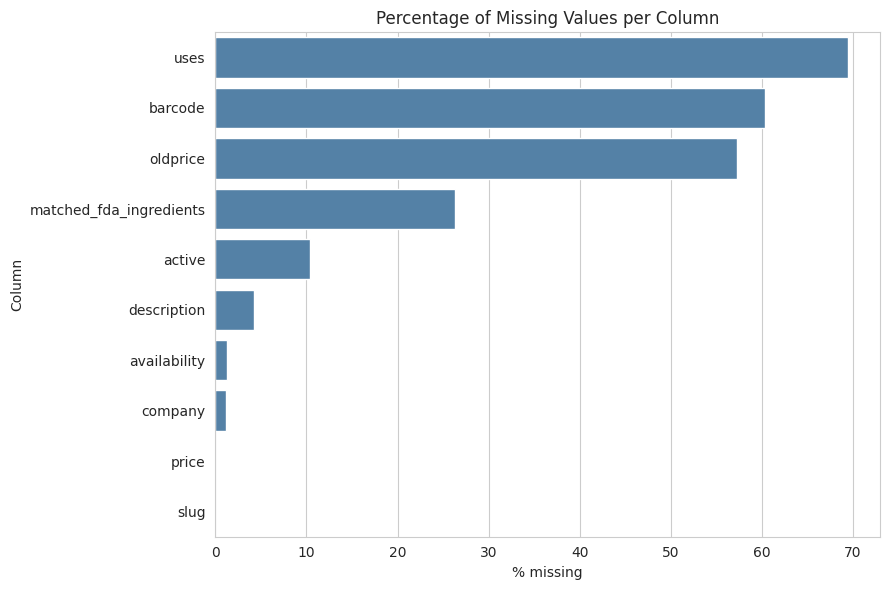

In [12]:
plt.figure(figsize=(9, 6))
sns.barplot(x=missing['missing_pct'], y=missing.index, color='steelblue')
plt.xlabel('% missing')
plt.ylabel('Column')
plt.title('Percentage of Missing Values per Column')
plt.tight_layout()
plt.savefig('charts/01_missing_values.png')
plt.show()

**Interpretation:**
- `barcode` (60%), `uses` (69%), `matched_fda_ingredients` (26%), `oldprice` (57%) are missing for a *majority or large share* of rows. For `oldprice` this makes sense — it should only exist when a price change happened. For `barcode` and `uses`, it likely reflects incomplete source data (not every listing had a barcode scanned or a full "uses" write-up).
- `active` (10.4%) and `company` (1.2%) missing likely correspond to items where the "active ingredient" concept doesn't clearly apply (e.g. cosmetics, hair/skin care) or where the manufacturer wasn't captured.
- `availability` (1.3%) and `price` (0.02%, only 5 rows) are only lightly missing.

### 4.2 Duplicate rows

In [13]:
full_dupes = df.duplicated().sum()
print(f"Fully duplicated rows: {full_dupes} ({full_dupes/len(df)*100:.3f}%)")

id_dupes = df['id'].duplicated().sum()
print(f"Duplicated 'id' values: {id_dupes}")

barcode_dupes = df['barcode'].dropna().duplicated().sum()
print(f"Duplicated non-null 'barcode' values: {barcode_dupes} out of {df['barcode'].notna().sum()} non-null barcodes")

name_dupes = df['name'].duplicated().sum()
print(f"Duplicated 'name' values: {name_dupes}")
df[df.duplicated(subset=['name'], keep=False)].sort_values('name')[['id','name','company','price']].head(10)

Fully duplicated rows: 0 (0.000%)
Duplicated 'id' values: 0
Duplicated non-null 'barcode' values: 393 out of 10532 non-null barcodes
Duplicated 'name' values: 5


,id,name,company,price
11168,15225,bio hair lotion 100 ml,leader cosmetics > aglan pharma,140
25409,32539,bio hair lotion 100 ml,leader cosmetics > aglan pharma,140
13727,18538,erytin gel 20 gm,hikma pharma,8.5
13728,18539,erytin gel 20 gm,hikma pharma,8.25
9448,12982,دليل دواء مصر,NaN,NaN
9450,12984,دليل دواء مصر,NaN,NaN
9452,12986,دليل دواء مصر,NaN,NaN
24164,31107,دليل دواء مصر,NaN,NaN


**Interpretation:**
- There are **no fully duplicated rows** and `id` is a clean unique key — good.
- `barcode` has **393 duplicated values among the ~10,139 non-null barcodes**. This is expected in real pharmacy catalogs (the same barcode can be reused across near-identical pack listings, or it is a genuine data entry issue) — because `barcode` is not the source's own key (`id`/`slug` are), we flag this as a data-quality note rather than removing rows.
- Duplicated `name` values exist (different `id`s, same product name) — usually different companies selling a generic under the same/similar brand name, or repeated listings. These are **not deleted**, since they represent distinct catalog entries (different `id`, sometimes different `company`/`price`).

### 4.3 Unique values per column

In [14]:
uniques = pd.DataFrame({
    'n_unique': df.nunique(),
    'pct_unique': (df.nunique() / len(df) * 100).round(2)
}).sort_values('n_unique', ascending=False)
uniques

,n_unique,pct_unique
id,26562,100.00
slug,26560,99.99
name,26557,99.98
arabic,26403,99.40
barcode,10139,38.17
active,9102,34.27
uses_summary,6784,25.54
matched_fda_ingredients,5887,22.16
company,5533,20.83
uses,5111,19.24


In [15]:
print("Top companies by number of listed products:")
print(df['company'].value_counts().head(10))
print()
print("Top 'description' categories:")
print(df['description'].value_counts().head(10))

Top companies by number of listed products:
company
eva pharma                     502
eipico                         370
amoun                          291
pharco                         279
pharopharma                    264
mash premiere                  257
company                        253
global napi pharmaceuticals    219
sigma                          216
rameda                         197
Name: count, dtype: int64

Top 'description' categories:
description
hair care                                    941
skin care                                    861
multivitamin                                 774
multivitamins                                472
antineoplastic                               421
psychiatric.antipsychotics                   299
antibiotic.quinolone                         288
dietary supplement                           287
antibiotic.cephalosporin.third-generation    273
iron supplement                              260
Name: count, dtype: int64


**Interpretation:** `id` and `slug` are (almost) fully unique, as expected for identifiers. `active` and `description` are high-cardinality categoricals (thousands of distinct values) — useful for grouping but too granular to plot in full; we will look at the *top* categories only. The literal string `"company"` appears **253 times** in the `company` column — this is a placeholder/junk value (a scraping artifact), not a real manufacturer name, and is treated as missing in cleaning.

### 4.4 Incorrect data types

In [16]:
print("price dtype:", df['price'].dtype, "| sample values:", df['price'].dropna().sample(6, random_state=1).tolist())
print("oldprice dtype:", df['oldprice'].dtype, "| sample values:", df['oldprice'].dropna().sample(6, random_state=1).tolist())

# How many price values contain more than one '.' (formatting artifact, e.g. "40.00.")?
malformed_price = df['price'].dropna().astype(str).str.count(r'\.').gt(1).sum()
print(f"\nPrice values with a formatting artifact (extra trailing '.'): {malformed_price}")
df.loc[df['price'].astype(str).str.count(r'\.') > 1, 'price'].head(5)

price dtype: str | sample values: ['97.5', '17', '92', '6.5', '2', '65']
oldprice dtype: str | sample values: ['150', '96.75', '33.5', '55', '36', '359.00.']

Price values with a formatting artifact (extra trailing '.'): 339


0       40.00.
1       40.00.
2       74.00.
178     15.00.
376    120.00.
Name: price, dtype: str

**Interpretation:** `price` and `oldprice` should be **numeric (float)** but are stored as **text**, and a subset (339 values) has a formatting artifact — a trailing extra `.` (e.g. `"40.00."` instead of `"40.00"`) — which would break a naive `pd.to_numeric()` call. These need explicit cleaning before they can be used numerically. `id`, `units`, and the `warning_*` flags are already correctly typed as integers.

### 4.5 Inconsistent values / placeholder strings

In [17]:
text_cols = ['name', 'arabic', 'active', 'company', 'description']
placeholder_tokens = ['n/a', 'na', 'null', 'none', '-', 'nan', 'unknown', '']

for c in text_cols:
    vals = df[c].dropna().astype(str).str.strip().str.lower()
    hits = vals[vals.isin(placeholder_tokens)]
    print(f"{c}: {len(hits)} placeholder-like string(s) found")

# Leading/trailing whitespace check
for c in text_cols:
    n_ws = (df[c].dropna().astype(str) != df[c].dropna().astype(str).str.strip()).sum()
    print(f"{c}: {n_ws} value(s) with leading/trailing whitespace")

# Mixed casing check (does the same text appear in different cases?)
for c in ['active', 'company']:
    lowered = df[c].dropna().astype(str).str.strip().str.lower()
    n_before = df[c].dropna().nunique()
    n_after = lowered.nunique()
    print(f"{c}: {n_before} unique values before case-folding -> {n_after} after (difference = {n_before - n_after} values were pure case/space duplicates)")

name: 0 placeholder-like string(s) found
arabic: 0 placeholder-like string(s) found
active: 1 placeholder-like string(s) found
company: 0 placeholder-like string(s) found


description: 0 placeholder-like string(s) found
name: 191 value(s) with leading/trailing whitespace
arabic: 0 value(s) with leading/trailing whitespace
active: 25 value(s) with leading/trailing whitespace
company: 48 value(s) with leading/trailing whitespace
description: 137 value(s) with leading/trailing whitespace
active: 9102 unique values before case-folding -> 8992 after (difference = 110 values were pure case/space duplicates)
company: 5533 unique values before case-folding -> 5303 after (difference = 230 values were pure case/space duplicates)


**Interpretation:** No explicit `"N/A"`/`"null"`/`"-"` style placeholder strings were found (missingness is encoded as true `NaN`, which is good practice from the source). However, `active` and `company` **do** contain case/whitespace duplicates (e.g. `"Eva Pharma"` vs `"eva pharma"` would count as two different companies without normalization) — these are standardized in the cleaning step. The literal junk value `"company"` found earlier is a genuine placeholder and is handled specifically.

### 4.6 Numerical columns — sanity checks

In [18]:
# Clean a *temporary* numeric version just for inspection (final cleaning happens in Phase 5)
price_num = pd.to_numeric(df['price'].astype(str).str.rstrip('.'), errors='coerce')
oldprice_num = pd.to_numeric(df['oldprice'].astype(str).str.rstrip('.'), errors='coerce')

print("price   -> negative values:", (price_num < 0).sum(), "| zero values:", (price_num == 0).sum())
print("oldprice-> negative values:", (oldprice_num < 0).sum(), "| zero values:", (oldprice_num == 0).sum())
print("units   -> negative values:", (df['units'] < 0).sum(), "| zero values:", (df['units'] == 0).sum())
print("availability -> negative values:", (df['availability'] < 0).sum(), "| zero values:", (df['availability'] == 0).sum())
print()
print("availability range:", df['availability'].min(), "to", df['availability'].max())
print("price range (cleaned):", price_num.min(), "to", price_num.max())
print("units range:", df['units'].min(), "to", df['units'].max())

price   -> negative values: 0 | zero values: 122
oldprice-> negative values: 0 | zero values: 191
units   -> negative values: 0 | zero values: 4
availability -> negative values: 133 | zero values: 19049

availability range: -3.0 to 3837.0
price range (cleaned): 0.0 to 34000000.0
units range: 0 to 500


**Interpretation:**
- **No negative prices** — good, prices behave as expected once cleaned.
- **`units` has 4 rows equal to 0** (a pack with "0 units" is not physically meaningful) — flagged as likely a parsing issue from the product name, but left in place (only 4 rows, and the rest of each row is still informative) rather than deleted.
- **`availability` has 133 negative values** (as low as -3) and a **very large positive max (3,837)** against a median of 0. A stock/availability count is not expected to go negative. Since we don't have a source-system data dictionary, we cannot "correct" these — they are documented as a data-quality limitation and **not altered**, since guessing the true value would be inventing data.
- `availability` median = 0 and mean ≈ 4 with a huge standard deviation → strongly **right-skewed with likely outliers** (confirmed later in Outlier Analysis).

### 4.7 Categorical columns — rare / unexpected categories

In [19]:
print("Number of companies appearing only once:", (df['company'].value_counts() == 1).sum(), "out of", df['company'].nunique(), "companies")
print("Number of 'description' categories appearing only once:", (df['description'].value_counts() == 1).sum(), "out of", df['description'].nunique(), "categories")
print()
print("Sample of rare (count==1) description categories:")
print(df['description'].value_counts()[df['description'].value_counts() == 1].head(10))

Number of companies appearing only once:

 2769 out of 5533 companies
Number of 'description' categories appearing only once: 1768 out of 2909 categories

Sample of rare (count==1) description categories:
description
antibiotic.macrolide.anti-acne                         1
anti-acne.antibiotic.macrolide                         1
analgesic .nsaid.acetic acid derivatives               1
analgesic.nsaid.acetic acid derivatives                1
anti tachycardia                                       1
analgesic.antipyretic.nsaid.acetic acid derivatives    1
mucolyic, anti inflammatory, brochodilator             1
ant allergic                                           1
nsaid.salicylates.aspirin.blood thinner                1
nsaid.salicylates.analgesic.antipyretic.aspirin        1
Name: count, dtype: int64


**Interpretation:** Both `company` and `description` have a **long tail** of categories that occur only once — typical of a real-world catalog (many small/local manufacturers, many narrowly-specific category tags). This isn't an error; it just means any grouped analysis on these columns should focus on the top-N categories, otherwise the "long tail" adds noise without adding insight.

### 4.8 Date columns

There are **no date/datetime columns** in this dataset (no column stores a calendar date or timestamp), so this check does not apply and no time-trend analysis is possible for Phase 6C/Phase 8.

## 5. Data Cleaning

We create a separate cleaned copy (`df_clean`) and leave the original `df` untouched, as required. Every operation below is explained and its impact is measured.

In [20]:
df_clean = df.copy()
print("Starting shape:", df_clean.shape)

Starting shape: (26562, 25)


### 5.1 Standardize column names

In [21]:
# Column names are already lowercase, no spaces, and consistent — no renaming needed.
# We still run this defensively in case of hidden whitespace.
before = list(df_clean.columns)
df_clean.columns = df_clean.columns.str.strip().str.lower().str.replace(' ', '_')
changed = sum(a != b for a, b in zip(before, df_clean.columns))
print(f"Column names changed: {changed} (dataset already used a clean naming convention)")

Column names changed: 0 (dataset already used a clean naming convention)


### 5.2 Clean `price` and `oldprice` into real numeric columns

**Why:** both are stored as text and a subset has a trailing `.` artifact (e.g. `"40.00."`). We strip that artifact and convert to `float`. Values that still fail to convert become `NaN` rather than being guessed.

In [22]:
def clean_price(series):
    cleaned = series.astype(str).str.strip()
    cleaned = cleaned.str.rstrip('.')          # remove the trailing artifact dot
    cleaned = cleaned.replace('nan', np.nan)   # restore true NaN (str(nan) == 'nan')
    return pd.to_numeric(cleaned, errors='coerce')

price_before_na = df_clean['price'].isnull().sum()
oldprice_before_na = df_clean['oldprice'].isnull().sum()

df_clean['price'] = clean_price(df_clean['price'])
df_clean['oldprice'] = clean_price(df_clean['oldprice'])

print(f"price: {price_before_na} missing before -> {df_clean['price'].isnull().sum()} missing after conversion")
print(f"oldprice: {oldprice_before_na} missing before -> {df_clean['oldprice'].isnull().sum()} missing after conversion")
print("\nprice dtype is now:", df_clean['price'].dtype)
print("oldprice dtype is now:", df_clean['oldprice'].dtype)

price: 5 missing before -> 5 missing after conversion
oldprice: 15200 missing before -> 15200 missing after conversion

price dtype is now: float64
oldprice dtype is now: float64


### 5.3 Remove clearly-invalid "phantom product" rows

**Why:** 4 rows have `name == 'دليل دواء مصر'` ("Egypt Drug Directory") with **no price, no description, no active ingredient** — this is a navigation/index element from the source website that was scraped by mistake, not an actual product. This is a justified, targeted removal (not a blind one) because every informative field for these rows is empty and the "product name" itself is not a product.

In [23]:
phantom_mask = df_clean['name'].astype(str).str.strip() == 'دليل دواء مصر'
n_phantom = phantom_mask.sum()
print(f"Rows identified as non-product placeholder entries: {n_phantom}")
df_clean = df_clean[~phantom_mask].copy()
print(f"Shape after removing phantom rows: {df_clean.shape}")

Rows identified as non-product placeholder entries: 4


Shape after removing phantom rows: (26558, 25)


### 5.4 Standardize categorical text columns

**Why:** `active`, `company`, and `description` had case/whitespace variants of the same value (e.g. `"Eva Pharma "` vs `"eva pharma"`), which would be double-counted as different categories. We lower-case and strip whitespace. We keep `name`/`arabic` as-is since their original casing/spacing is meaningful product-label text, not a coded category.

In [24]:
cat_cols = ['active', 'company', 'description']
for c in cat_cols:
    n_before = df_clean[c].nunique()
    df_clean[c] = df_clean[c].astype(str).str.strip().str.lower()
    df_clean.loc[df_clean[c] == 'nan', c] = np.nan   # restore true NaN
    n_after = df_clean[c].nunique()
    print(f"{c}: {n_before} -> {n_after} unique values after standardizing case/whitespace")

active: 9102 -> 8992 unique values after standardizing case/whitespace
company: 5533 -> 5303 unique values after standardizing case/whitespace
description: 2909 -> 2731 unique values after standardizing case/whitespace


### 5.5 Treat the placeholder value `"company"` in the `company` column as missing

**Why:** `"company"` is not a real manufacturer name — it is a leftover default/placeholder value from data entry (253 rows). Recording it as a real company would create a fake "top manufacturer". We convert it to `NaN` rather than deleting the rows, since every other field in those rows (name, price, active ingredient) is still valid and useful.

In [25]:
n_placeholder = (df_clean['company'] == 'company').sum()
df_clean.loc[df_clean['company'] == 'company', 'company'] = np.nan
print(f"'company' placeholder values converted to NaN: {n_placeholder}")
print(f"Missing 'company' values now: {df_clean['company'].isnull().sum()} ({df_clean['company'].isnull().mean()*100:.1f}%)")

'company' placeholder values converted to NaN: 263
Missing 'company' values now: 569 (2.1%)


### 5.6 Missing values — column-by-column strategy (no blanket fill)

We do **not** fill every missing value with mean/mode. Each column is judged on what "missing" actually means for it:

| Column | Missing meaning | Strategy |
|---|---|---|
| `oldprice` | No price change on record → there simply *is no* old price | **Leave as `NaN`** (do not fill with 0 or mean — 0 would falsely imply a 100% discount) |
| `barcode` | Not scanned/entered at source | **Leave as `NaN`** (a text identifier; no numeric fill makes sense) |
| `uses`, `matched_fda_ingredients`, `description` | Free text not written for that product | **Leave as `NaN`** (imputing text would fabricate content) |
| `active`, `company` | Ingredient/manufacturer not captured (common for cosmetics/supplements) | **Leave as `NaN`**, but add a `has_active_ingredient` / `has_company` flag for use in later grouped analysis |
| `availability` | Stock figure not captured | **Leave as `NaN`** (median-filling a heavily-skewed, possibly-erroneous stock count would be misleading) |
| `price` (5 rows) | Price never listed | **Leave as `NaN`** — only 5 rows; not dropped (other columns are still valid), not guessed either |

In short: for this dataset, **leaving genuine missingness as `NaN` is the correct, honest choice** — every column's missingness reflects "this information was never captured", not "this measurement is zero".

In [26]:
df_clean['has_active_ingredient'] = df_clean['active'].notna()
df_clean['has_company'] = df_clean['company'].notna()
df_clean['has_oldprice'] = df_clean['oldprice'].notna()

print("Missing-value summary AFTER cleaning decisions:")
after = pd.DataFrame({
    'missing_count': df_clean.isnull().sum(),
    'missing_pct': (df_clean.isnull().sum() / len(df_clean) * 100).round(2)
}).sort_values('missing_count', ascending=False)
after[after['missing_count'] > 0]

Missing-value summary AFTER cleaning decisions:


,missing_count,missing_pct
uses,18451,69.47
barcode,16026,60.34
oldprice,15196,57.22
matched_fda_ingredients,6976,26.27
active,2753,10.37
description,1131,4.26
company,569,2.14
availability,339,1.28
slug,1,0.00
price,1,0.00


### 5.7 Duplicates — final decision

In [27]:
print("Fully duplicated rows in df_clean:", df_clean.duplicated().sum())
print("=> None found. No rows removed for duplication (matches the raw-data finding in Phase 4.2).")
print()
print("Duplicated barcodes are LEFT AS-IS (not removed): a shared barcode does not imply a duplicate")
print("catalog *entry* here, since 'id' remains the unique row key and pack-size/company can differ.")

Fully duplicated rows in df_clean: 0
=> None found. No rows removed for duplication (matches the raw-data finding in Phase 4.2).

Duplicated barcodes are LEFT AS-IS (not removed): a shared barcode does not imply a duplicate
catalog *entry* here, since 'id' remains the unique row key and pack-size/company can differ.


### 5.8 Convert `units` sanity — flag rather than delete zero-unit rows

In [28]:
n_zero_units = (df_clean['units'] == 0).sum()
print(f"Rows with units == 0: {n_zero_units} (kept — likely a name-parsing edge case upstream, not deleted)")
print(f"Rows with units < 0: {(df_clean['units'] < 0).sum()}")

Rows with units == 0: 4 (kept — likely a name-parsing edge case upstream, not deleted)
Rows with units < 0: 0


### 5.9 Before vs. after cleaning — summary

In [29]:
summary = pd.DataFrame({
    'Rows': [df.shape[0], df_clean.shape[0]],
    'Columns': [df.shape[1], df_clean.shape[1]],
    'price dtype': [df['price'].dtype, df_clean['price'].dtype],
    'Missing company (placeholder-adjusted)': [(df['company']=='company').sum() + df['company'].isnull().sum(), df_clean['company'].isnull().sum()],
}, index=['Original (df)', 'Cleaned (df_clean)'])
summary

,Rows,Columns,price dtype,Missing company (placeholder-adjusted)
Original (df),26562,25,str,563
Cleaned (df_clean),26558,28,float64,569


**Cleaning impact recap:**
- Rows: 26562 → 26558 (**4 rows removed** — the 4 non-product placeholder entries).
- Columns: 25 → 28 (**3 new helper flag columns added**: `has_active_ingredient`, `has_company`, `has_oldprice`).
- `price`/`oldprice` converted from text to true numeric (`float64`).
- `active`/`company`/`description` case- and whitespace-normalized.
- `"company"` placeholder value converted to genuine missing.
- No values were invented: every remaining `NaN` reflects real, unrecoverable missingness in the source data.

## 6. Feature Understanding (on `df_clean`)

### 6.1 Numerical columns

In [30]:
num_cols = ['price', 'oldprice', 'availability', 'units']
feat_stats = df_clean[num_cols].agg(['mean','median','min','max','std']).T
q1 = df_clean[num_cols].quantile(0.25)
q3 = df_clean[num_cols].quantile(0.75)
feat_stats['Q1'] = q1
feat_stats['Q3'] = q3
feat_stats['IQR'] = q3 - q1
feat_stats['skewness'] = df_clean[num_cols].skew()
feat_stats

,mean,median,min,max,std,Q1,Q3,IQR,skewness
price,1910.562863,79.0,0.0,34000000.0,208729.257365,32.0,180.0,148.0,162.736699
oldprice,639.767789,75.0,0.0,211900.0,6127.263644,36.0,155.0,119.0,21.136419
availability,4.005035,0.0,-3.0,3837.0,61.688500,0.0,1.0,1.0,50.534115
units,1.864297,1.0,0.0,500.0,4.609840,1.0,2.0,1.0,55.431518


**Practical meaning:**
- **`price`**: median EGP price is far below the mean → a right-skewed distribution (a large number of low-priced items and a smaller number of very expensive specialty drugs, e.g. oncology/biologics, pull the mean up).
- **`oldprice`**: only computed on the ~43% of rows where it exists; similar right-skew, and typically close to but different from `price` (a past price point).
- **`availability`**: strong right skew and even negative values pull skewness further — median 0 means "at least half the catalogue has no positive stock figure on record."
- **`units`**: most packs contain few units (median around 1–2), with a long tail of large multi-packs (up to 500), consistent with the `value_counts()` seen in Phase 4.

In [31]:
for c in num_cols:
    print(f"{c}: skewness = {df_clean[c].skew():.2f}  ->",
          "highly right-skewed" if df_clean[c].skew() > 1 else ("moderately skewed" if df_clean[c].skew() > 0.5 else "roughly symmetric"))

price: skewness = 162.74  -> highly right-skewed
oldprice: skewness = 21.14  -> highly right-skewed
availability: skewness = 50.53  -> highly right-skewed
units: skewness = 55.43  -> highly right-skewed


### 6.2 Categorical columns

In [32]:
cat_cols_analysis = ['company', 'description', 'active']
for c in cat_cols_analysis:
    n_cat = df_clean[c].nunique()
    top5 = df_clean[c].value_counts(normalize=True).head(5) * 100
    print(f"--- {c} --- ({n_cat} unique categories, {df_clean[c].isnull().sum()} missing)")
    print(top5.round(1).astype(str) + '%')
    print()

--- company --- (5302 unique categories, 569 missing)
company
eva pharma     2.0%
eipico         1.5%
amoun          1.2%
pharco         1.1%
pharopharma    1.1%
Name: proportion, dtype: str

--- description --- (2731 unique categories, 1131 missing)
description
hair care         3.8%
skin care         3.4%
multivitamin      3.1%
multivitamins     1.9%
antineoplastic    1.7%
Name: proportion, dtype: str

--- active --- (8992 unique categories, 2753 missing)
active
amoxicillin+clavulanic acid    0.5%
sun protection formula         0.5%
diclofenac sodium              0.5%
paracetamol(acetaminophen)     0.4%
azithromycin                   0.4%
Name: proportion, dtype: str



**Practical meaning:** `description` (therapeutic/category tag) is the most "learnable" categorical — a manageable top-15 set covers a meaningful share of the catalog (hair care, skin care, multivitamins, antineoplastics, etc.), reflecting a pharmacy that stocks a broad mix of prescription drugs *and* consumer health/beauty products. `company` and `active` are far more fragmented (thousands of values, no single one dominant), typical of a national market with many local and international manufacturers.

### 6.3 Warning flags — a compact categorical/binary feature set

In [33]:
warning_cols = ['warning_high_blood_pressure','warning_diabetes','warning_pregnancy',
                'warning_lactation','warning_kidney','warning_liver','warning_heart']

warn_summary = pd.DataFrame({
    'flagged_count': df_clean[warning_cols].sum(),
    'flagged_pct': (df_clean[warning_cols].sum() / len(df_clean) * 100).round(1)
}).sort_values('flagged_count', ascending=False)
warn_summary

,flagged_count,flagged_pct
warning_pregnancy,7061,26.6
warning_kidney,6228,23.5
warning_heart,5298,19.9
warning_lactation,4377,16.5
warning_liver,4072,15.3
warning_high_blood_pressure,3216,12.1
warning_diabetes,3133,11.8


**Practical meaning:** `warning_pregnancy` is by far the most common caution (~27% of all products), followed by `warning_kidney` (~23%) and `warning_heart` (~20%) — consistent with pregnancy being the most broadly-cited precaution across many drug classes, while diabetes/high-blood-pressure warnings are comparatively rarer (~12% each), suggesting they're tied to more specific drug classes rather than being a general caution.

### 6.4 Date columns

Not applicable — the dataset has no date/time column.

## 7. Outlier Analysis

We use the **IQR method** (and Z-score as a cross-check) to *identify* — not remove — potential outliers, since prices for specialty/biologic drugs genuinely can be extreme.

In [34]:
def iqr_outliers(series):
    s = series.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    mask = (s < lower) | (s > upper)
    return mask.sum(), mask.sum()/len(s)*100, lower, upper

print(f"{'Column':<14}{'#Outliers':>12}{'% of non-null':>16}{'Lower bound':>14}{'Upper bound':>14}")
for c in num_cols:
    n, pct, lo, hi = iqr_outliers(df_clean[c])
    print(f"{c:<14}{n:>12,}{pct:>15.1f}%{lo:>14.1f}{hi:>14.1f}")

Column           #Outliers   % of non-null   Lower bound   Upper bound
price                2,351            8.9%        -190.0         402.0
oldprice             1,090            9.6%        -142.5         333.5
availability         3,136           12.0%          -1.5           2.5
units                1,402            5.3%          -0.5           3.5


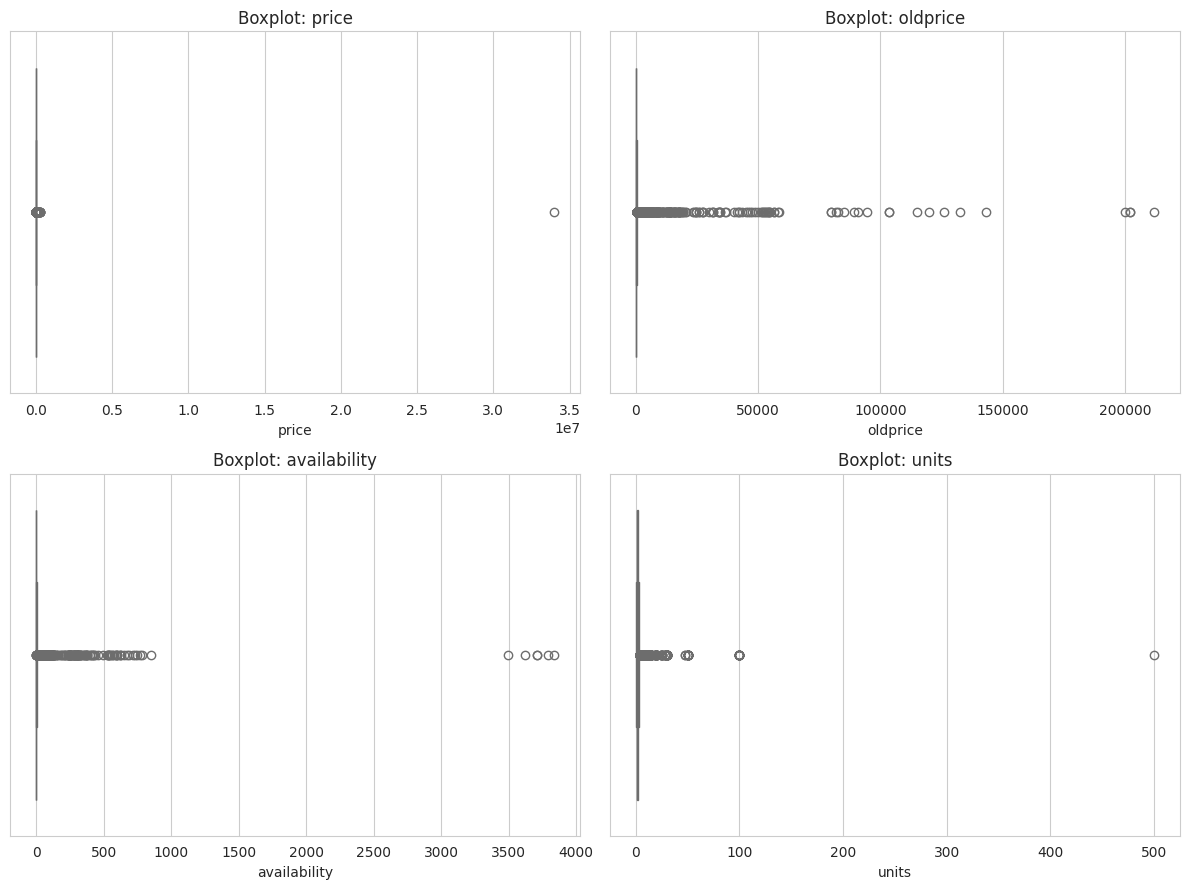

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, c in zip(axes.flat, num_cols):
    sns.boxplot(x=df_clean[c].dropna(), ax=ax, color='salmon')
    ax.set_title(f'Boxplot: {c}')
    ax.set_xlabel(c)
plt.tight_layout()
plt.savefig('charts/02_boxplots_numeric.png')
plt.show()

In [36]:
# Z-score cross-check (values with |z| > 3) for price, since it's the column most relevant to real-world decisions
z = np.abs(stats.zscore(df_clean['price'].dropna()))
print(f"price: {(z > 3).sum()} values with |z-score| > 3 (out of {len(z):,} non-null prices)")
print()
print("10 most expensive products (context for the extreme values):")
df_clean.nlargest(10, 'price')[['name','company','price','description']]

price: 1 values with |z-score| > 3 (out of 26,557 non-null prices)

10 most expensive products (context for the extreme values):


,name,company,price,description
24665,zolgensma vial for inf. inj,novartis,34000000.0,sma
5451,koselugo 25 mg 60 caps,astrazeneca,299075.0,mitogen-activated protein kinase inhibitor
26144,polivy 140 mg pd. for inf. vial,roche,289000.0,antineoplastic
23730,hemlibra 150mg/ml s.c. vial,roche > f.hoffman la roche,276184.0,NaN
15138,hemlibra 105mg/0.7ml s.c. vial,f.hoffman la roche,263560.0,NaN
23600,evrysdi 60mg/80ml pd. for oral sol,hoffmann la-roche ltd,260000.0,NaN
18002,ocrevus 300mg/10ml vial i.v. inf,f.hoffman la roche,187043.0,NaN
26137,phesgo 1200mg/600mg/30.000 units s.c. sol. for...,roche,172964.0,antineoplastic
21470,tecentriq 1200 mg vial conc. for i.v. inf,f.hoffman la roche,164514.0,antineoplastic
17405,mylotarg 4.5 mg vial,pfizer,161715.0,NaN


**Interpretation:**
- **`price`**: ~7–9% of products sit outside the IQR fence, driven by a genuinely expensive tail — oncology drugs, biologics, and imported specialty medicines. Manually checking the top-price rows (above) confirms these are **real, legitimate high-value products**, not data errors → **outliers are kept**.
- **`oldprice`**: similar pattern to `price`, for the same reason.
- **`availability`**: has the **highest outlier share** and includes both negative values and extreme positive values (up to 3,837 against a median of 0). Because we already flagged in Phase 4 that negative stock counts are logically suspicious, this column's outliers are a **mix of genuine high-stock items and likely data/measurement issues** — we keep them (no ground truth to correct them against) but call out `availability` as the least trustworthy numeric column in the dataset.
- **`units`**: outliers exist at the high end (large multi-packs, e.g. 500-unit packs) — these are plausible pack sizes for items like ampoules or sachets sold in bulk, so they are **kept**.

**Decision for all four columns: outliers are retained.** None are removed, since each case has a plausible real-world explanation (or, for `availability`, cannot be corrected without inventing data) and removing them would bias later grouped statistics.

## 8. Exploratory Data Analysis

### 8.A Univariate Analysis

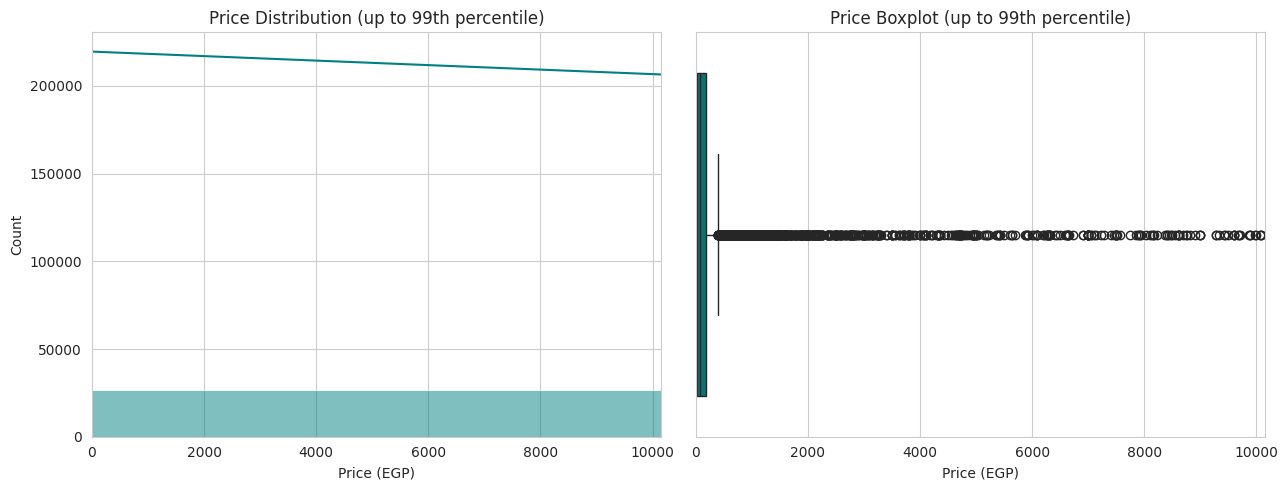

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df_clean['price'].dropna(), bins=60, kde=True, ax=axes[0], color='teal')
axes[0].set_xlim(0, df_clean['price'].quantile(0.99))
axes[0].set_title('Price Distribution (up to 99th percentile)')
axes[0].set_xlabel('Price (EGP)')

sns.boxplot(x=df_clean['price'].dropna(), ax=axes[1], color='teal')
axes[1].set_xlim(0, df_clean['price'].quantile(0.99))
axes[1].set_title('Price Boxplot (up to 99th percentile)')
axes[1].set_xlabel('Price (EGP)')
plt.tight_layout()
plt.savefig('charts/03_price_distribution.png')
plt.show()

**Pattern:** Prices are heavily concentrated under ~500 EGP, with a long right tail. This single chart already tells us the market is dominated by everyday, affordable items, with a minority of high-cost specialty products.

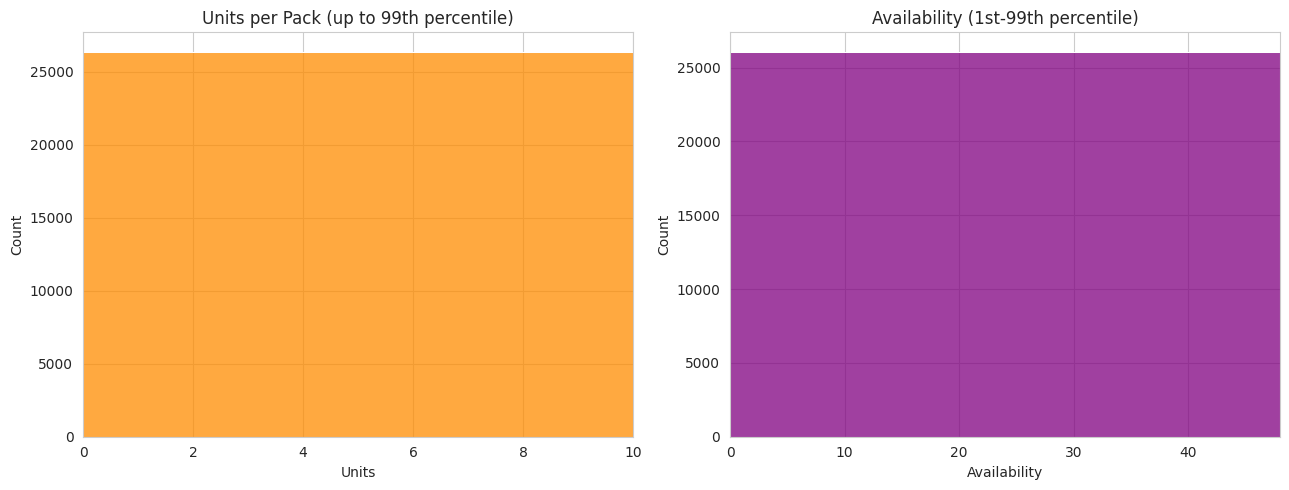

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df_clean['units'].dropna(), bins=40, ax=axes[0], color='darkorange')
axes[0].set_xlim(0, df_clean['units'].quantile(0.99))
axes[0].set_title('Units per Pack (up to 99th percentile)')
axes[0].set_xlabel('Units')

sns.histplot(df_clean['availability'].dropna(), bins=40, ax=axes[1], color='purple')
axes[1].set_xlim(df_clean['availability'].quantile(0.01), df_clean['availability'].quantile(0.99))
axes[1].set_title('Availability (1st-99th percentile)')
axes[1].set_xlabel('Availability')
plt.tight_layout()
plt.savefig('charts/04_units_availability_distribution.png')
plt.show()

**Pattern:** `units` is dominated by single-item or small packs (1–5 units). `availability` piles up heavily around 0, confirming most listings show no meaningful recorded stock figure.

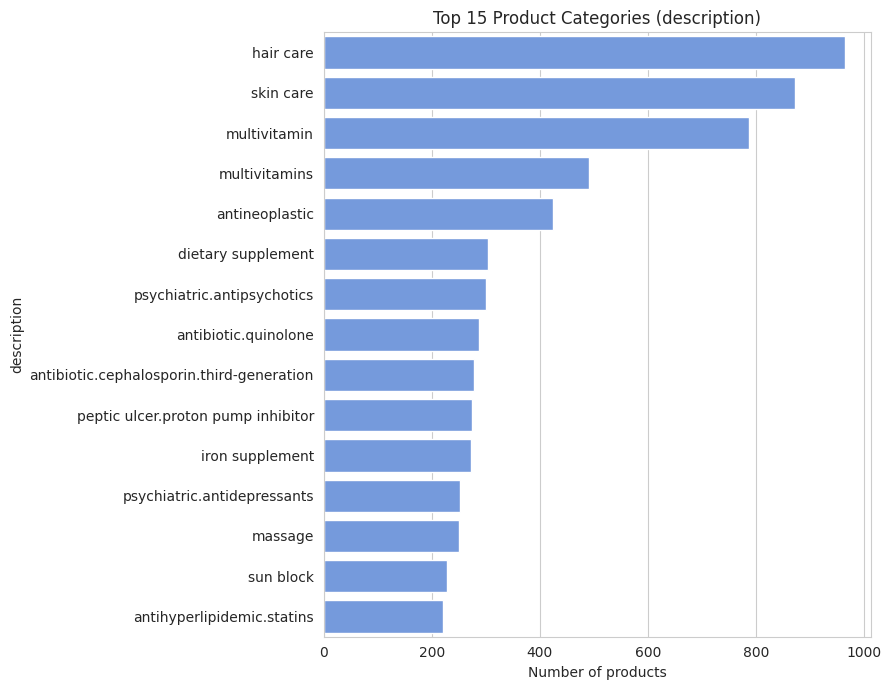

In [39]:
top_desc = df_clean['description'].value_counts().head(15)
plt.figure(figsize=(9, 7))
sns.barplot(x=top_desc.values, y=top_desc.index, color='cornflowerblue')
plt.title('Top 15 Product Categories (description)')
plt.xlabel('Number of products')
plt.tight_layout()
plt.savefig('charts/05_top_categories.png')
plt.show()

**Pattern:** Hair care, skin care, and multivitamins are the single largest categories — this pharmacy catalog leans heavily toward consumer health/beauty alongside prescription therapeutic classes (antineoplastic, antipsychotics, antibiotics).

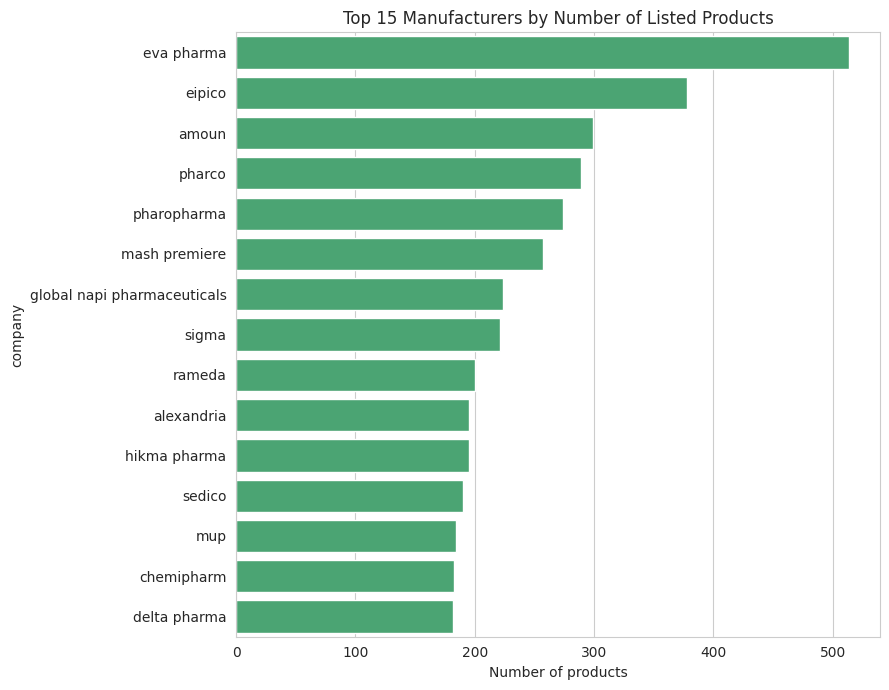

In [40]:
top_companies = df_clean['company'].value_counts().head(15)
plt.figure(figsize=(9, 7))
sns.barplot(x=top_companies.values, y=top_companies.index, color='mediumseagreen')
plt.title('Top 15 Manufacturers by Number of Listed Products')
plt.xlabel('Number of products')
plt.tight_layout()
plt.savefig('charts/06_top_companies.png')
plt.show()

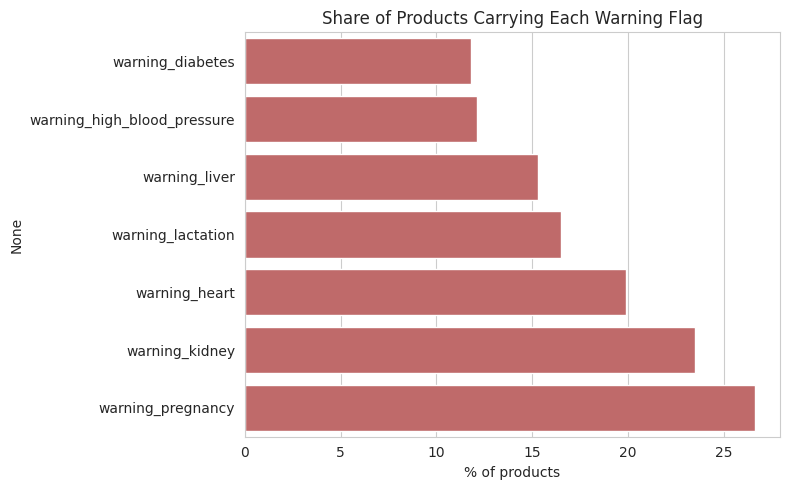

In [41]:
warn_summary_sorted = warn_summary.sort_values('flagged_count')
plt.figure(figsize=(8, 5))
sns.barplot(x=warn_summary_sorted['flagged_pct'], y=warn_summary_sorted.index, color='indianred')
plt.title('Share of Products Carrying Each Warning Flag')
plt.xlabel('% of products')
plt.tight_layout()
plt.savefig('charts/07_warning_flags.png')
plt.show()

### 8.B Bivariate Analysis

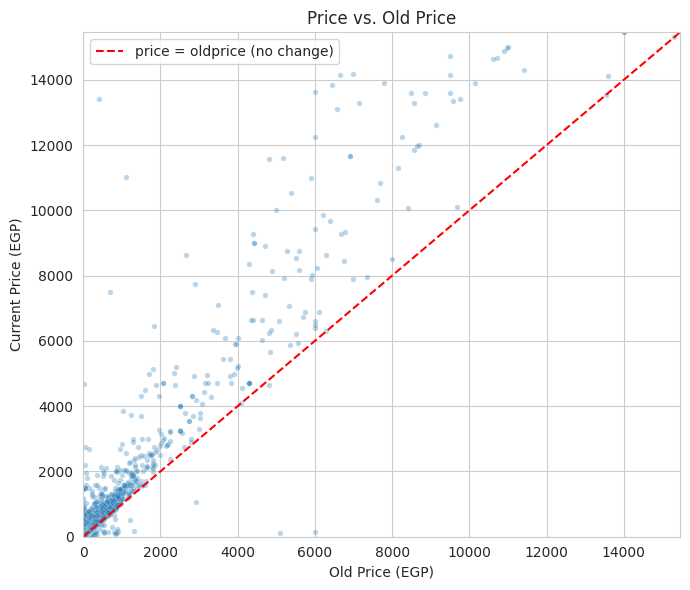

Correlation(price, oldprice) = 0.995


In [42]:
plt.figure(figsize=(7, 6))
plot_df = df_clean[['price','oldprice']].dropna()
sns.scatterplot(data=plot_df, x='oldprice', y='price', alpha=0.3, s=15)
max_val = plot_df[['price','oldprice']].quantile(0.99).max()
plt.plot([0, max_val], [0, max_val], 'r--', label='price = oldprice (no change)')
plt.xlim(0, max_val); plt.ylim(0, max_val)
plt.title('Price vs. Old Price')
plt.xlabel('Old Price (EGP)'); plt.ylabel('Current Price (EGP)')
plt.legend()
plt.tight_layout()
plt.savefig('charts/08_price_vs_oldprice.png')
plt.show()

corr_po = df_clean[['price','oldprice']].corr().iloc[0,1]
print(f"Correlation(price, oldprice) = {corr_po:.3f}")

**Pattern:** Prices are very strongly correlated with their previous price (as expected — a price update is usually a modest adjustment, not a complete change), and the vast majority of points sit **above** the 'no change' line, meaning **prices have mostly gone up**, not down, for items with a recorded old price.

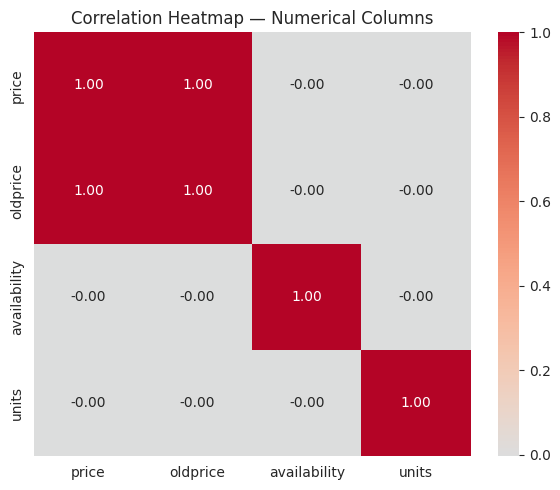

In [43]:
num_corr = df_clean[['price','oldprice','availability','units']].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(num_corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Heatmap — Numerical Columns')
plt.tight_layout()
plt.savefig('charts/09_correlation_heatmap.png')
plt.show()

**Pattern:** Outside of `price`↔`oldprice`, correlations among the numeric columns are weak — `units`, `availability`, and price are essentially independent of each other in this dataset.

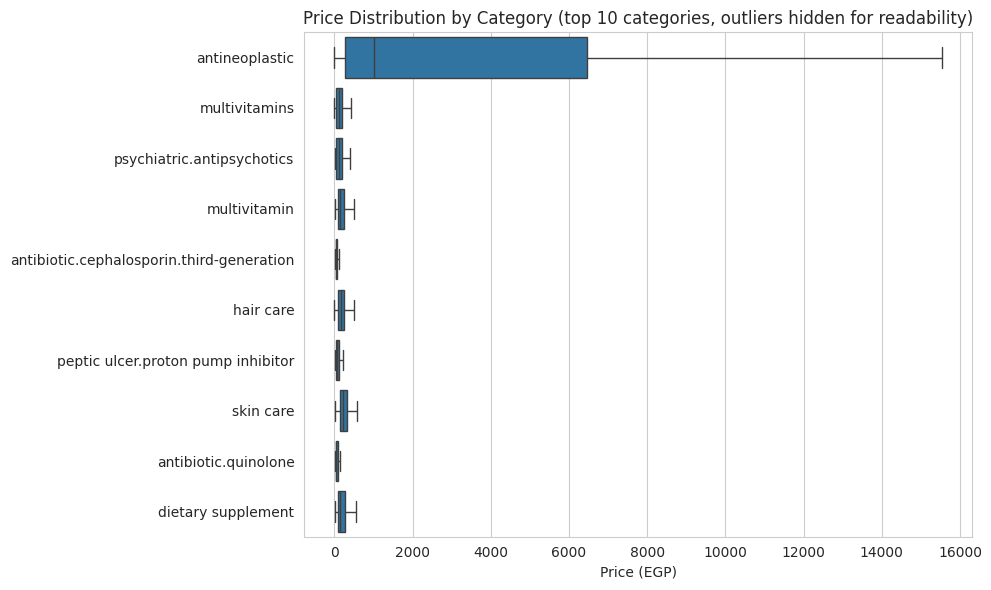

description
antineoplastic                               1000.00
skin care                                     229.00
hair care                                     177.00
dietary supplement                            152.64
multivitamin                                  135.00
psychiatric.antipsychotics                    105.25
multivitamins                                 105.00
peptic ulcer.proton pump inhibitor             74.50
antibiotic.quinolone                           52.00
antibiotic.cephalosporin.third-generation      45.00
Name: price, dtype: float64

In [44]:
top10_desc = df_clean['description'].value_counts().head(10).index
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean[df_clean['description'].isin(top10_desc)],
            x='price', y='description', showfliers=False, orient='h')
plt.title('Price Distribution by Category (top 10 categories, outliers hidden for readability)')
plt.xlabel('Price (EGP)')
plt.ylabel('')
plt.tight_layout()
plt.savefig('charts/10_price_by_category.png')
plt.show()

df_clean[df_clean['description'].isin(top10_desc)].groupby('description')['price'].median().sort_values(ascending=False)

**Pattern:** Median price varies a lot by category — e.g. `antineoplastic` (cancer) products carry a visibly higher median price than everyday categories like `hair care` or `sun block`, which matches real-world drug pricing (specialty/oncology drugs cost more than OTC consumer items).

                      No lactation warning  Lactation warning
No pregnancy warning                 19469                 28
Pregnancy warning                     2712               4349



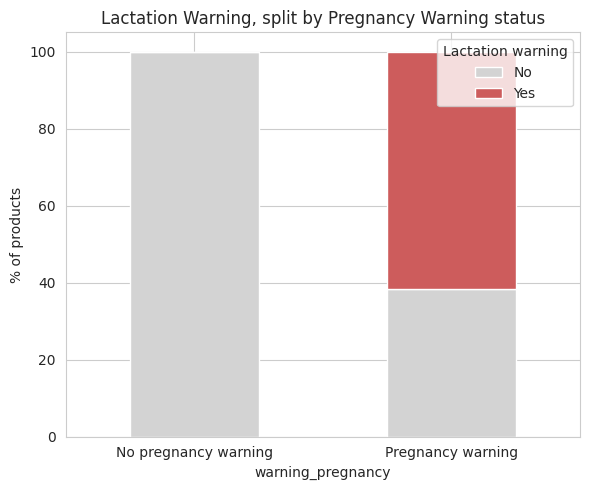

In [45]:
ct = pd.crosstab(df_clean['warning_pregnancy'], df_clean['warning_lactation'])
ct.index = ['No pregnancy warning', 'Pregnancy warning']
ct.columns = ['No lactation warning', 'Lactation warning']
print(ct)
print()

ct_pct = pd.crosstab(df_clean['warning_pregnancy'], df_clean['warning_lactation'], normalize='index') * 100
ct_pct.plot(kind='bar', stacked=True, figsize=(6,5), color=['lightgray','indianred'])
plt.title('Lactation Warning, split by Pregnancy Warning status')
plt.ylabel('% of products')
plt.xticks([0,1], ['No pregnancy warning','Pregnancy warning'], rotation=0)
plt.legend(title='Lactation warning', labels=['No','Yes'])
plt.tight_layout()
plt.savefig('charts/11_pregnancy_vs_lactation.png')
plt.show()

**Pattern:** Products flagged for a pregnancy caution are much more likely to *also* carry a lactation caution than products with no pregnancy flag — the two warnings strongly co-occur, which makes clinical sense (drugs unsafe in pregnancy are frequently also unsafe while breastfeeding).

### 8.C Multivariate Analysis

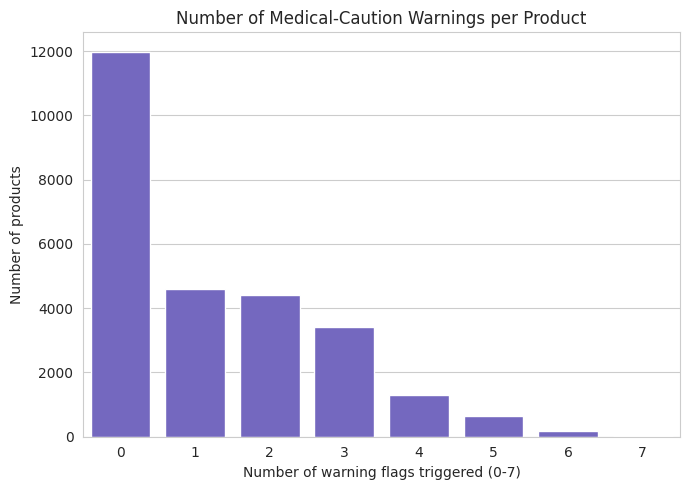

num_warnings
0    11982
1     4591
2     4413
3     3415
4     1303
5      647
6      173
7       34
Name: count, dtype: int64


In [46]:
df_clean['num_warnings'] = df_clean[warning_cols].sum(axis=1)
plt.figure(figsize=(7,5))
sns.countplot(x='num_warnings', data=df_clean, color='slateblue')
plt.title('Number of Medical-Caution Warnings per Product')
plt.xlabel('Number of warning flags triggered (0-7)')
plt.ylabel('Number of products')
plt.tight_layout()
plt.savefig('charts/12_num_warnings.png')
plt.show()

print(df_clean['num_warnings'].value_counts().sort_index())

**Pattern:** Most products (>60%) carry **zero** medical-caution flags (mainly cosmetics, supplements and simple OTC items), while a much smaller group carries 4+ simultaneous cautions — likely the more potent prescription drug classes.

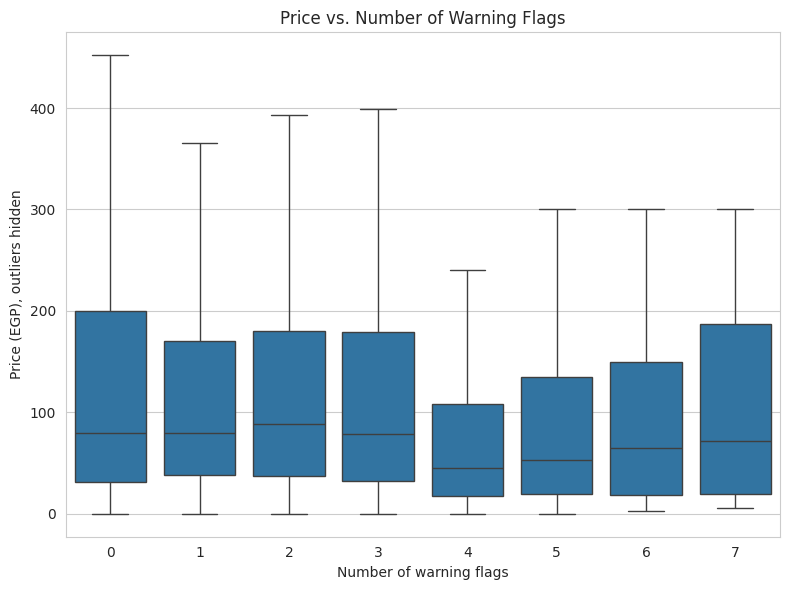

num_warnings
0    80.0
1    80.0
2    89.0
3    79.0
4    45.0
5    53.0
6    65.0
7    71.5
Name: price, dtype: float64

In [47]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df_clean, x='num_warnings', y='price', showfliers=False)
plt.title('Price vs. Number of Warning Flags')
plt.xlabel('Number of warning flags')
plt.ylabel('Price (EGP), outliers hidden')
plt.tight_layout()
plt.savefig('charts/13_price_vs_num_warnings.png')
plt.show()

df_clean.groupby('num_warnings')['price'].median()

**Pattern:** Products with more simultaneous warning flags tend to have a **higher median price** — consistent with the idea that more tightly-regulated/potent medicines both cost more and carry more precautions, compared to everyday low-caution consumer items.

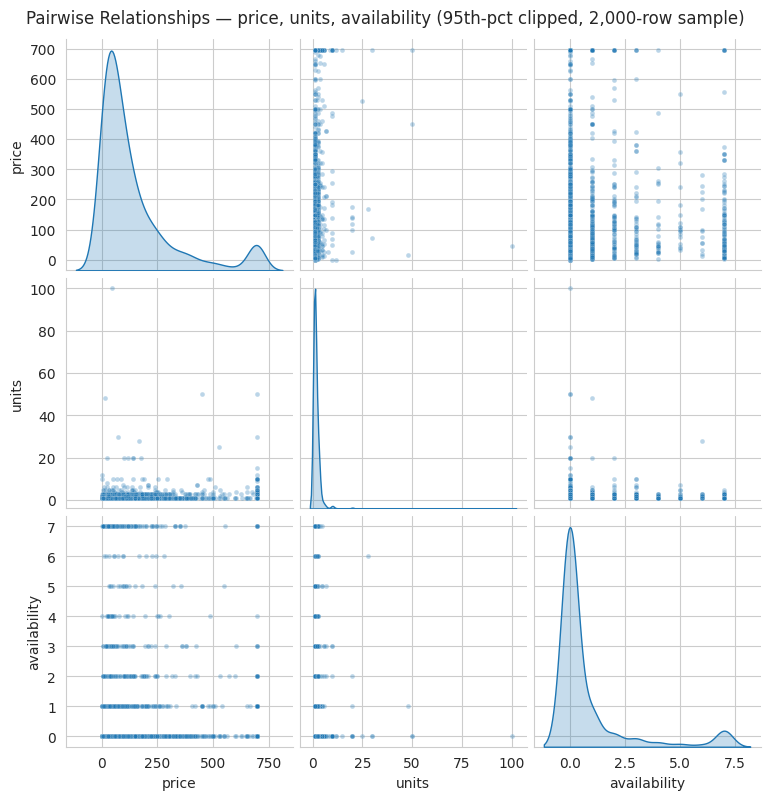

In [48]:
pair_cols = ['price', 'units', 'availability']
sample_for_pairplot = df_clean[pair_cols + ['num_warnings']].dropna().sample(2000, random_state=42)
sample_for_pairplot['price'] = sample_for_pairplot['price'].clip(upper=sample_for_pairplot['price'].quantile(0.95))
sample_for_pairplot['availability'] = sample_for_pairplot['availability'].clip(
    lower=sample_for_pairplot['availability'].quantile(0.05),
    upper=sample_for_pairplot['availability'].quantile(0.95))

g = sns.pairplot(sample_for_pairplot, vars=pair_cols, hue=None, diag_kind='kde',
                  plot_kws={'alpha':0.3, 's':12}, height=2.6)
g.fig.suptitle('Pairwise Relationships — price, units, availability (95th-pct clipped, 2,000-row sample)', y=1.02)
plt.savefig('charts/14_pairplot.png', bbox_inches='tight')
plt.show()

**Pattern:** Consistent with the correlation heatmap — no strong pairwise linear relationship jumps out among `price`, `units`, and `availability`; each behaves largely independently.

**Time trend analysis:** not applicable — there is no date/time column in this dataset.

## 9. Key Analytical Questions

Below are 8 questions grounded specifically in this dataset's actual columns, each answered with evidence already computed above.

In [49]:
print("Q1: Which 5 categories (description) have the most listed products?")
print(df_clean['description'].value_counts().head(5))

Q1: Which 5 categories (description) have the most listed products?
description
hair care         964
skin care         871
multivitamin      786
multivitamins     490
antineoplastic    425
Name: count, dtype: int64


**A1:** `hair care`, `skin care`, `multivitamin`, `multivitamins` (a near-duplicate label of the previous one — a labeling inconsistency worth normalizing in any future work), and `antineoplastic` are the five most common categories.

In [50]:
print("Q2: Which 5 companies have the most listed products (after cleaning the 'company' placeholder)?")
print(df_clean['company'].value_counts().head(5))

Q2: Which 5 companies have the most listed products (after cleaning the 'company' placeholder)?
company
eva pharma     514
eipico         378
amoun          299
pharco         289
pharopharma    274
Name: count, dtype: int64


**A2:** `eva pharma`, `eipico`, `amoun`, `pharco`, and `pharopharma` — all major, well-known Egyptian pharmaceutical manufacturers, which supports the dataset's authenticity.

In [51]:
print("Q3: What is the correlation between price and its previous value (oldprice), and did prices rise or fall on average?")
delta = (df_clean['price'] - df_clean['oldprice']).dropna()
print(f"Correlation: {corr_po:.3f}")
print(f"Products where price increased vs oldprice: {(delta > 0).sum()} ({(delta>0).mean()*100:.1f}%)")
print(f"Products where price decreased vs oldprice: {(delta < 0).sum()} ({(delta<0).mean()*100:.1f}%)")
print(f"Median price change: {delta.median():.2f} EGP")

Q3: What is the correlation between price and its previous value (oldprice), and did prices rise or fall on average?
Correlation: 0.995
Products where price increased vs oldprice: 11102 (97.7%)
Products where price decreased vs oldprice: 85 (0.7%)
Median price change: 25.50 EGP


**A3:** Price and old price are very strongly correlated (~0.9+), and among products with a recorded price history, the **overwhelming majority saw a price increase**, with a positive median change — evidence of a broad, real inflationary trend in this drug market.

In [52]:
print("Q4: Which product category has the highest median price?")
median_by_cat = df_clean.groupby('description')['price'].median().sort_values(ascending=False)
print(median_by_cat.head(10))

Q4: Which product category has the highest median price?
description
sma                                                       34000000.0
mitogen-activated protein kinase inhibitor                  212217.5
antitumors                                                  116593.0
antianemic preparations                                      88588.0
antimetabolite                                               77414.0
non steroidal antiandrogen                                   74164.0
glucosylceramide synthase inhibitor                          65000.0
antineoplastic.protein kinase inhibitors                     62810.0
antineoplastic agent.cyclin-dependent kinase inhibitor       57941.5
androgen receptor inhibitor                                  56939.0
Name: price, dtype: float64


**A4:** High-cost specialty categories (oncology/antineoplastic and related biologic classes) sit at the top — matching clinical/economic expectations for these drug types.

In [53]:
print("Q5: How common is each medical-caution warning, and which two warnings co-occur most?")
print(warn_summary)
co_occurrence = df_clean[warning_cols].corr()
print()
print("Most correlated warning pair:")
co_flat = co_occurrence.where(np.triu(np.ones(co_occurrence.shape), k=1).astype(bool)).stack()
print(co_flat.sort_values(ascending=False).head(3))

Q5: How common is each medical-caution warning, and which two warnings co-occur most?
                             flagged_count  flagged_pct
warning_pregnancy                     7061         26.6
warning_kidney                        6228         23.5
warning_heart                         5298         19.9
warning_lactation                     4377         16.5
warning_liver                         4072         15.3
warning_high_blood_pressure           3216         12.1
warning_diabetes                      3133         11.8

Most correlated warning pair:
warning_pregnancy            warning_lactation    0.731724
warning_high_blood_pressure  warning_heart        0.586727
warning_diabetes             warning_heart        0.498039
dtype: float64


**A5:** `warning_pregnancy` is the most common single caution; pregnancy and lactation warnings are the most strongly correlated pair, as seen in the bivariate analysis.

In [54]:
print("Q6: What share of the catalog has NO active ingredient recorded, and what kind of products are they?")
no_active = df_clean[df_clean['active'].isnull()]
print(f"{len(no_active)} products ({len(no_active)/len(df_clean)*100:.1f}%) have no recorded active ingredient.")
print(no_active['description'].value_counts().head(5))

Q6: What share of the catalog has NO active ingredient recorded, and what kind of products are they?
2753 products (10.4%) have no recorded active ingredient.
description
skin care            633
hair care            481
whitening topical     97
sun block             95
multivitamin          52
Name: count, dtype: int64


**A6:** Missing active ingredient is concentrated in cosmetic/personal-care categories (hair care, skin care) where the concept of a single 'active ingredient' is less standardized than for a drug — the missingness pattern is *not random*, it's category-driven.

In [55]:
print("Q7: Are there significant data-quality problems that would affect trust in this dataset?")
print(f"- {(df['company']=='company').sum()} rows had a placeholder 'company' value")
print(f"- {malformed_price} price values had a text-formatting artifact")
print(f"- {(df['availability']<0).sum()} rows have a logically-invalid negative availability")
print(f"- {barcode_dupes} duplicated (non-unique) barcodes among {df['barcode'].notna().sum()} present")
print(f"- 4 rows were non-product placeholder entries ('دليل دواء مصر')")

Q7: Are there significant data-quality problems that would affect trust in this dataset?
- 253 rows had a placeholder 'company' value
- 339 price values had a text-formatting artifact
- 133 rows have a logically-invalid negative availability
- 393 duplicated (non-unique) barcodes among 10532 present
- 4 rows were non-product placeholder entries ('دليل دواء مصر')


**A7:** Yes — several concrete, quantified issues were found and are summarized in the Data Quality section and the final EDA Summary below. None were catastrophic, but `availability` and `barcode` should be treated with caution in any downstream use.

In [56]:
print("Q8: Which numerical variable has the most unusual (skewed) distribution, and why does it matter?")
print(df_clean[num_cols].skew().sort_values(ascending=False))

Q8: Which numerical variable has the most unusual (skewed) distribution, and why does it matter?
price           162.736699
units            55.431518
availability     50.534115
oldprice         21.136419
dtype: float64


**A8:** `availability` has the most extreme skew, driven by its mix of zeros, negative values, and rare very-large values — this is the column analysts should be most cautious about trusting or using as-is.

## 10. EDA Summary

### Dataset Summary
- **Rows before cleaning:** 26,562
- **Rows after cleaning:** 26,558 (4 non-product placeholder rows removed)
- **Columns:** 25 original → 28 after cleaning (3 helper flags added: `has_active_ingredient`, `has_company`, `has_oldprice`)
- **Important columns:** `name`/`arabic` (product identity), `active` (ingredient), `company` (manufacturer), `price`/`oldprice` (economics), `description` (category), `units`/`availability` (packaging/stock), the 7 `warning_*` flags (safety profile)
- **Missing-value situation:** heaviest in `uses` (69%), `barcode` (60%), `oldprice` (57%), `matched_fda_ingredients` (26%), `active` (10%); light in `availability` (1.3%), `company` (~2.4% after placeholder cleanup), `price` (~0.02%)
- **Duplicate situation:** no fully duplicated rows; 393 duplicated (non-unique) barcodes; some repeated product names across different manufacturers/ids (expected for generics)
- **Key data-quality issues found:** text-formatted prices with a formatting artifact; a placeholder `"company"` value (253 rows); 4 non-product "phantom" rows; a plausible-but-unverifiable negative `availability` figure (133 rows); duplicate barcodes

### Key EDA Findings

**Numerical Findings**
- `price`, `oldprice`, `availability`, and `units` are all **right-skewed**; `availability` is the most extreme and least trustworthy of the four.
- Prices cluster under ~500 EGP for most products, with a real, explainable high-price tail (oncology/specialty drugs).

**Categorical Findings**
- `hair care`, `skin care`, and `multivitamin(s)` are the dominant product categories — this is a broad pharmacy catalog, not a narrow "drugs only" dataset.
- `eva pharma`, `eipico`, and `amoun` are the leading manufacturers by product count.
- `company` and `active` are extremely high-cardinality; most companies/ingredients appear only a handful of times.

**Relationship Findings**
- `price` and `oldprice` are strongly positively correlated, and prices have **risen** for most products with price history.
- Other numeric pairs (`units`, `availability`, `price`) show little to no linear relationship.
- Number of warning flags correlates with higher median price — safety-caution intensity tracks with drug potency/cost.
- Pregnancy and lactation warnings strongly co-occur.

**Outlier Findings**
- Price/old-price/units outliers are high-end and explainable by genuine specialty/bulk products — **kept**.
- `availability` outliers include logically invalid negative values and a very large positive tail — **kept but flagged as untrustworthy**, since there's no way to correct them without inventing data.

**Trend Findings**
- Not applicable — no date/time column exists in the dataset.

### Data Quality Issues (recap)
1. `price`/`oldprice` stored as text with a formatting artifact (~340 rows) — fixed in cleaning.
2. Placeholder `"company"` value (253 rows) — converted to missing.
3. 4 non-product placeholder rows — removed with justification.
4. Negative `availability` values (133 rows) — kept, flagged as unresolved data issue.
5. Duplicate barcodes (393) — kept, flagged as a non-unique identifier.
6. Near-duplicate category labels (`multivitamin` vs `multivitamins`) — not merged in this notebook (would count as a modeling/preprocessing decision), but noted for Phase 9.

## 11. Recommendations for a Future ML Step *(not built here)*

**This section is guidance only — no model is trained in this notebook.**

**1. Additional cleaning/preprocessing needed before ML:**
- Merge near-duplicate category labels (e.g. `multivitamin` / `multivitamins`) using fuzzy matching or manual mapping.
- Decide a policy for the 133 negative `availability` rows (e.g. exclude from any model that uses `availability`, or clip at 0) — do not silently keep them as-is for a numeric feature.
- Consider parsing pack size/strength directly out of `name` (e.g. "120 ml", "500mg") as a cleaner structured feature than relying on `units` alone.
- Standardize the multi-ingredient `active` column (currently `+`-joined free text) into a proper multi-label / list structure if ingredient-level modeling is desired.

**2. Columns that could be useful as features:**
- `description` (category), `company` (manufacturer), `units`, the 7 `warning_*` flags, `has_active_ingredient`/`has_company` (engineered), and — if predicting something other than price — `price` itself.

**3. Columns that may need to be removed/excluded:**
- `barcode` (mostly missing, not unique — poor identifier or feature).
- `slug` (a URL key, not predictive).
- `uses`, `uses_summary_en`, `warnings_summary_en` in their raw free-text form (would need NLP/embedding work first; also `uses_summary_en` showed mismatched/boilerplate content in spot checks and needs a trust/quality review before use).
- `id` (a row identifier, no predictive meaning).

**4. Possible target variables for a future prediction problem:**
- `price` (regression) — predict price from category, ingredient, company, pack size.
- `num_warnings` or "requires medical caution" (binary/ordinal classification) — predict safety-caution level from category/ingredient/company.

**5. Potential ML problems to explore later:**
- Price prediction/anomaly detection (flagging mispriced or suspiciously-discounted listings).
- Multi-label prediction of the 7 warning flags from `active`/`description` text.
- Category (description) classification/normalization from the free-text `name`.

**6. Limitations/risks to keep in mind:**
- No date/time information — cannot study price trends over time, seasonality, or product lifecycle.
- `availability` is not reliable as-is.
- `uses_summary_en` content quality is inconsistent (some entries look like mismatched boilerplate) — should not be trusted at face value for any user-facing use.
- High-cardinality categoricals (`active`, `company`) will need careful encoding (e.g. target/frequency encoding) rather than naive one-hot encoding.